# Проектирование ТВД 150 л.с. при πк = 6

Одна ступень турбины компрессора и одна ступень свободной силовой турбины.


# Расчёт цикла двигателя

### Прототипы:
- tj100
- ТВД150 МКБ «Гранит»
- Honeywell TPE331

## 1. Импорт библиотек, исходные данные

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

#-------------------------------------------
pd.set_option('display.max_rows', None)      #чтобы было видно все строки в pandas
pd.set_option('display.max_columns', None)
# Десятичный вывод с 4 знаками после точки; точность вычислений сохраняется.
pd.set_option('display.float_format', '{:.4f}'.format)
#-------------------------------------------

# Мощность двигателя
power_hp = 150.0
HP_TO_KW = 0.73549875
power_kw = power_hp * HP_TO_KW

# Наружные условия
T_a = 288.0          # K
p_a = 101.3          # кПа
velocity = 0.0       # м/с

# Температура газа перед турбиной
T_g = 1250.0         # K

# КПД и потери
eta_k_poly = 0.86    # п кпд цбк по методичке 0.85..0.87
eta_gg_poly = 0.90   # п кпд газогенератора
eta_pt_poly = 0.90   # п кпд силовой турбины

sigma_in = 0.985
sigma_burn = 0.965
eta_burn = 0.98

eta_m_gg = 0.99
eta_m_pt = 0.99

# КПД редуктора:
eta_red = 0.98

# Отборы воздуха
g_leak = 0.005
g_cool = 0.0

# Топливо и газовые постоянные
Q_lhv = 43000.0      # кДж/кг
l0 = 14.61
T_ref = 288.0        # K
R_air = 0.287        # кДж/(кг К)
R_gas = 0.288        # кДж/(кг К)

# Сопло и выход из свободной турбины
pi_nozzle_static = 1.04
c_pt_exit = 250.0    # м/с
phi_nozzle = 0.95
beta_prop = 15.0     # Н/кВт
eta_prop = 0.82

# Настройки вариантного расчёта
n_variants = 801

KCAL_TO_KJ = 4.187

print(f"Мощность на валу: {power_hp:.0f} л.с. = {power_kw:.3f} кВт")

Мощность на валу: 150 л.с. = 110.325 кВт


## 2. Теплофизические свойства

Формулы теплоёмкостей взяты из приложения 6 методички. Для воздуха используется предел alpha → infty

**Формулы следующей ячейки: теплофизические свойства и деление пополам**

Обозначения: $T$ — К, $\alpha$ — коэффициент избытка воздуха, $a=1/\alpha$; для воздуха $a=0$. Теплоёмкости — **кДж/(кг·К)**. В коде `cp_i` — истинная, `cp_m` — средняя теплоёмкость.

Вспомогательные полиномы температуры:

$$U=2.5\cdot10^{-3}T-0.875,\qquad V=2.5\cdot10^{-5}T^2-0.0275T+6.5625,$$
$$W=1.176\cdot10^{-3}T-0.88235,\qquad Z=5.5556\cdot10^{-6}T^2-0.013056T+6.67.$$

$$c_{pi}(T,\alpha)=4.187\begin{cases}
0.0174a+0.2407+(0.0093a+0.0193)U+\left(0.002-\dfrac{0.001056a}{1-0.2a}\right)V,&T<750,\\[2mm]
0.0267a+0.26+(0.0133a+0.032)W-\left(0.00374+\dfrac{0.0094a^2}{1+10a^2}\right)Z,&T\ge750.
\end{cases}$$

$$
c_{pm}(T,\alpha)=4.187\begin{cases}
\dfrac{2.25a+1.2}{10^5}(T-70)+0.236,&T<700,\\
\dfrac{1.25a+2.2}{10^5}(T+450)+0.218,&T\ge700.
\end{cases}
$$

Функции энтальпии записаны **точно как в существующем коде**:

$$h(T,\alpha)=c_{pm}(T,\alpha)T,\qquad
\Delta h(T,\alpha)=h(T,\alpha)-h(T_{ref},\alpha).$$

`process_properties` использует приближение:

$$T_m=\frac{T_1+T_2}{2},\qquad c_p=c_{pi}(T_m,\alpha),\qquad k=\frac{c_p}{c_p-R}.$$

В `bisect` решается $F(x)=0$: $m=(l+r)/2$; если $F(l)F(m)\le0$, заменяем $r=m$, иначе $l=m$. После 80 шагов возвращается $(l+r)/2$. Это выбранный численный алгоритм, не отдельная физическая формула.

**Источник:** «цикл.pdf», приложение 6, с. 56–57; согласование свойств процесса — §2.3, с. 16. Определения `h`, `dh` и правила осреднения показаны здесь для объяснения уже имеющегося кода, без изменения его модели.


In [2]:
def cp_i(T, alpha=np.inf):
    if np.isinf(alpha):
        a = 0.0
    else:
        a = 1.0 / alpha

    if T < 750.0:
        value = ((0.0174*a + 0.2407)
                 + (0.0093*a + 0.0193)*(2.5e-3*T - 0.875)
                 + (2.0e-3 - 1.056e-3*a/(1.0 - 0.2*a))
                 * (2.5e-5*T*T - 0.0275*T + 6.5625))
    else:
        value = ((0.0267*a + 0.26)
                 + (0.0133*a + 0.032)*(1.176e-3*T - 0.88235)
                 - (0.374e-2 + 0.94e-2*a*a/(1.0 + 10*a*a))
                 * (5.5556e-6*T*T - 1.3056e-2*T + 6.67))

    return KCAL_TO_KJ * value


def cp_m(T, alpha=np.inf):
    a = 0.0 if np.isinf(alpha) else 1.0 / alpha

    if T < 700.0:
        value = (2.25*a + 1.2)/1e5*(T - 70.0) + 0.236
    else:
        value = (1.25*a + 2.2)/1e5*(T + 450.0) + 0.218

    return KCAL_TO_KJ * value


def h(T, alpha=np.inf):
    return cp_m(T, alpha) * T


def dh(T, alpha):
    return h(T, alpha) - h(T_ref, alpha)


def process_properties(T1, T2, alpha, R):
    T_mean = (T1 + T2) / 2
    cp = cp_i(T_mean, alpha)
    k = cp / (cp - R)
    return cp, k


def bisect(fun, left, right, n=80):
    f_left = fun(left)

    for _ in range(n):
        middle = (left + right) / 2
        f_middle = fun(middle)

        if f_left * f_middle <= 0:
            right = middle
        else:
            left = middle
            f_left = f_middle

    return (left + right) / 2

## 3. Входное устройство

**Формулы следующей функции `inlet()`**

$T_a,p_a,V$ — статические параметры атмосферы и скорость полёта. Индекс 2 — вход компрессора; возвращаемые $T_2,p_2$ — **полные** параметры.

$$c_p=c_{pi}\left(\frac{T_a+T_2}{2},\infty\right),\qquad k=\frac{c_p}{c_p-R_a},$$
$$c_p(T_2-T_a)=\frac{V^2}{2000},\qquad
M=\frac{V}{\sqrt{1000kR_aT_a}},$$
$$\pi_V=\left(\frac{T_2}{T_a}\right)^{k/(k-1)},\qquad
p_2=p_a\pi_V\sigma_{in}.$$

$T_2$ находится делением пополам. Числа 1000 и 2000 связаны с использованием кДж. При $V=0$: $T_2=T_a$, $\pi_V=1$.

**Источник:** «цикл.pdf», §2.1, с. 10 — полные параметры на входе и коэффициент сохранения давления. Выражения через $V$ — раскрытие перехода от статических к полным параметрам, уже реализованное в исходном ноутбуке.


In [3]:
def inlet():
    def equation(T2):
        cp, k = process_properties(T_a, T2, np.inf, R_air)
        return T2 - T_a - velocity**2/(2000*cp)

    T2 = bisect(equation, T_a, T_a + velocity**2/1000 + 1)
    cp, k = process_properties(T_a, T2, np.inf, R_air)

    M = velocity / math.sqrt(1000*k*R_air*T_a)
    pi_v = (T2/T_a)**(k/(k-1))
    p2 = p_a * pi_v * sigma_in

    return {
        'T2': T2,
        'p2': p2,
        'pi_v': pi_v,
        'M_flight': M,
        'cp_in': cp,
        'k_in': k
    }

## 4. Компрессор

**Формулы следующей функции `compressor()`**

$\pi_k=p_3/p_2$ — степень повышения полного давления; $\eta_{kp}$ — политропический КПД. Свойства определяются по средней температуре $T_m=(T_2+T_3)/2$.

$$c_p=c_{pi}(T_m,\infty),\quad k=\frac{c_p}{c_p-R_a},\quad
T_3=T_2\pi_k^{(k-1)/(k\eta_{kp})},$$
$$\eta_k=\frac{\pi_k^{(k-1)/k}-1}{\pi_k^{(k-1)/(k\eta_{kp})}-1},\qquad
p_3=p_2\pi_k,\qquad L_k=c_p(T_3-T_2).$$

$T_3$ решается неявно, поскольку $c_p$ и $k$ зависят от неё. В коде `expm1(x)` означает $e^x-1$ и сохраняет точность при малом $x$.

**Источник:** «цикл.pdf», с. 9 — переход от политропического КПД к адиабатному; §2.2, с. 11–12 — параметры и работа компрессора. Формула $T_3$ — преобразование этих соотношений.


In [4]:
def compressor(pi_k, inp):
    T2 = inp['T2']

    def equation(T3):
        cp, k = process_properties(T2, T3, np.inf, R_air)
        return T3 - T2*pi_k**((k-1)/(k*eta_k_poly))

    T3 = bisect(equation, T2, T_g)
    cp, k = process_properties(T2, T3, np.inf, R_air)

    x = (k-1)/k * math.log(pi_k)
    eta_k = math.expm1(x) / math.expm1(x/eta_k_poly)

    p3 = inp['p2'] * pi_k
    L_k = cp * (T3 - T2)

    return {
        'T3': T3,
        'p3': p3,
        'L_k': L_k,
        'cp_k': cp,
        'k_k': k,
        'eta_k': eta_k
    }

## 5. Камера сгорания

**Формулы следующей функции `combustor()`**

`gm` — расход топлива, отнесённый к воздуху, поступающему в камеру сгорания. $h$ и $\Delta h$ — функции предыдущего раздела. В числителе существующего кода используется $h(T,\infty)$:

$$D_Q=Q_H\eta_b-(1+l_0)\Delta h(T_g,1)+l_0\Delta h(T_g,\infty),$$
$$g_m=\frac{h(T_g,\infty)-h(T_3,\infty)}{D_Q},\qquad
\alpha=\frac{1}{g_ml_0}.$$

Доли расходов относительно воздуха через компрессор:

$$b=1-g_{ут}-g_{охл},\qquad
f=bg_m,\qquad g_g=b(1+g_m),\qquad p_g=p_3\sigma_b.$$

Соответствие коду: `fuel_air` $=f$, `gas_air` $=g_g$, `pg` $=p_g$.

**Источник:** «цикл.pdf», §3.1, с. 19–21 — уточнённый расход топлива и состав продуктов сгорания; §3.2, с. 22 — относительные расходы. Формулы записаны в форме реализованной функции, без изменения исходного расчёта.


In [5]:
def combustor(comp):
    denominator = (Q_lhv*eta_burn
                   - (1+l0)*dh(T_g, 1)
                   + l0*dh(T_g, np.inf))

    gm = (h(T_g) - h(comp['T3'])) / denominator
    alpha = 1 / (gm*l0)

    b = 1 - g_leak - g_cool
    fuel_air = b * gm
    gas_air = b * (1 + gm)
    pg = comp['p3'] * sigma_burn

    return {
        'Tg': T_g,
        'pg': pg,
        'gm': gm,
        'alpha': alpha,
        'b': b,
        'fuel_air': fuel_air,
        'gas_air': gas_air
    }

## 6. Турбина компрессора

**Формулы следующих функций `turbine_eta()` и `gas_generator_turbine()`**

Для произвольной турбины при $\pi_t=p_{in}^*/p_{out}^*$ и политропическом КПД $\eta_{tp}$:

$$\eta_t^*=\frac{1-\pi_t^{-(k-1)\eta_{tp}/k}}{1-\pi_t^{-(k-1)/k}}.$$

Для турбины компрессора (ТК, газогенератора):

$$L_{ГГ}=\frac{L_k}{g_g\eta_{m,ГГ}},\qquad
c_p=c_{pi}\left(\frac{T_g+T_4}{2},\alpha\right),\qquad k=\frac{c_p}{c_p-R_g},$$
$$c_p(T_g-T_4)=L_{ГГ},\qquad
\pi_{ГГ}=\left(\frac{T_g}{T_4}\right)^{k/[(k-1)\eta_{p,ГГ}]},\qquad
p_4=\frac{p_g}{\pi_{ГГ}}.$$

Температуры и давления здесь полные. $T_4$ находится из баланса работы; затем рассчитывается адиабатный КПД функцией `turbine_eta`.

**Источник:** «цикл.pdf», с. 9 — пересчёт КПД; с. 17–19 — баланс мощностей и параметры компрессорной турбины. Формула $\pi_{ГГ}$ — преобразование политропического соотношения.


In [6]:
def turbine_eta(pi_t, k, eta_poly):
    x = -(k-1)/k * math.log(pi_t)
    return math.expm1(x*eta_poly) / math.expm1(x)


def gas_generator_turbine(comp, burn):
    L_gg = comp['L_k'] / (burn['gas_air'] * eta_m_gg)

    def equation(T4):
        cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)
        return cp*(T_g - T4) - L_gg

    T4 = bisect(equation, T_a, T_g)
    cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)

    pi_gg = (T_g/T4)**(k/((k-1)*eta_gg_poly))
    p4 = burn['pg'] / pi_gg
    eta_gg = turbine_eta(pi_gg, k, eta_gg_poly)

    return {
        'T4': T4,
        'p4': p4,
        'L_gg': L_gg,
        'pi_gg': pi_gg,
        'cp_gg': cp,
        'k_gg': k,
        'eta_gg': eta_gg
    }

## 7. Свободная силовая турбина

**Формулы следующих функций `static_from_total()` и `power_turbine()`**

Переход от полных параметров к статическим при скорости $c$:

$$c_p=c_{pi}\left(\frac{T^*+T}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g},\quad
c_p(T^*-T)=\frac{c^2}{2000},$$
$$M=\frac{c}{\sqrt{1000kR_gT}},\qquad r=\frac{p^*}{p}=\left(\frac{T^*}{T}\right)^{k/(k-1)}.$$

Для силовой турбины в модели цикла задаются статическое давление и выходная скорость:

$$p_5=\pi_{с,стат}\,p_a,\qquad c_5=c_{pt,exit},\qquad p_5^*=p_5r_5.$$

Неизвестная $T_5^*$ определяется совместно с переходом к статическим параметрам:

$$T_5^*=T_4\left(\frac{p_5^*}{p_4}\right)^{(k-1)\eta_{p,СТ}/k},\qquad
c_p=c_{pi}\left(\frac{T_4+T_5^*}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g}.$$

После решения:

$$\pi_{СТ}=\frac{p_4}{p_5^*},\quad L_{СТ}=c_p(T_4-T_5^*),\quad
\pi_{с}=\frac{p_5^*}{p_a},\quad
\eta_{СТ}^*=\frac{1-\pi_{СТ}^{-(k-1)\eta_{p,СТ}/k}}{1-\pi_{СТ}^{-(k-1)/k}}.$$

**Источник:** «цикл.pdf», с. 9 и §2.3, с. 16–19. Полное давление $p_5^*$ и статическое $p_5$ — разные величины; связь раскрыта по энергетическому и изоэнтропическому соотношениям, используемым исходным кодом. Значения $\pi_{с,стат}$ и $c_5$ — входные решения проекта.


In [7]:
def static_from_total(T_total, c, alpha, R):
    def equation(T_static):
        cp, k = process_properties(T_total, T_static, alpha, R)
        return cp*(T_total - T_static) - c*c/2000

    T_static = bisect(equation, 100.0, T_total)
    cp, k = process_properties(T_total, T_static, alpha, R)

    M = c / math.sqrt(1000*k*R*T_static)
    pressure_ratio = (T_total/T_static)**(k/(k-1))

    return T_static, cp, k, M, pressure_ratio


def power_turbine(gg, burn):
    p5 = pi_nozzle_static * p_a

    def equation(T5_total):
        T5, cp5, k5, M5, ratio5 = static_from_total(
            T5_total, c_pt_exit, burn['alpha'], R_gas
        )
        p5_total = p5 * ratio5
        cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)

        return T5_total - gg['T4']*(p5_total/gg['p4'])**((k-1)*eta_pt_poly/k)

    T5_total = bisect(equation, max(200.0, T_a), gg['T4'])

    T5, cp5, k5, M5, ratio5 = static_from_total(
        T5_total, c_pt_exit, burn['alpha'], R_gas
    )
    p5_total = p5 * ratio5

    cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)
    pi_pt = gg['p4'] / p5_total
    L_pt = cp * (gg['T4'] - T5_total)
    eta_pt = turbine_eta(pi_pt, k, eta_pt_poly)

    return {
        'T5_total': T5_total,
        'p5_total': p5_total,
        'T5': T5,
        'p5': p5,
        'M5': M5,
        'cp5': cp5,
        'k5': k5,
        'pi_nozzle': p5_total/p_a,
        'L_pt': L_pt,
        'pi_pt': pi_pt,
        'cp_pt': cp,
        'k_pt': k,
        'eta_pt': eta_pt
    }

## 8. Реактивное сопло

**Формулы следующей функции `nozzle()`**

Для существующей модели полного расширения до $p_a$:

$$\pi_с=\frac{p_5^*}{p_a},\qquad
H_с=c_pT_5^*\left(1-\pi_с^{-(k-1)/k}\right),$$
$$T_с=T_5^*-\frac{\varphi_с^2H_с}{c_p},\qquad
c_с=\varphi_с\sqrt{2000H_с},\qquad p_с=p_a.$$

Свойства уточняются по $(T_5^*+T_с)/2$. Удельная тяга сопла, отнесённая к расходу воздуха:

$$R_{уд}=g_g(c_с-V).$$

**Источник:** «цикл.pdf», §3.2, с. 24–27 — реактивное сопло и удельная тяга. Это описание действующей функции: она предполагает полное расширение и не содержит отдельной ветви запертого сопла и члена $(p_с-p_a)A_с$. Код в рамках добавления формул не изменяется.


In [8]:
def nozzle(pt, burn):
    ratio = pt['pi_nozzle']

    def equation(Tc):
        cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)
        H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
        return Tc - pt['T5_total'] + phi_nozzle**2*H/cp

    Tc = bisect(equation, 100.0, pt['T5_total'])
    cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)

    H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
    c_nozzle = phi_nozzle * math.sqrt(2000*H)
    R_specific = burn['gas_air'] * (c_nozzle - velocity)

    return {
        'Tc': Tc,
        'pc': p_a,
        'H_nozzle': H,
        'c_nozzle': c_nozzle,
        'cp_nozzle': cp,
        'k_nozzle': k,
        'R_specific': R_specific
    }

## 9. Мощность и расходы

**Формулы следующей функции `performance()`**

Работы — кДж/кг, мощности — кВт; $G$ — кг/с.

$$N_{уд}=g_gL_{СТ}\eta_{m,СТ}\eta_r,\qquad
G_в=\frac{N_e}{N_{уд}},\qquad G_{в,г}=bG_в,$$
$$G_f=g_mG_{в,г},\qquad G_g=g_gG_в,\qquad G_{f,ч}=3600G_f,\qquad R_с=G_вR_{уд}.$$

Добавка эквивалентной мощности в существующем коде:

$$\Delta N_{уд}=\begin{cases}
R_{уд}/\beta_{винт},&V=0,\\
R_{уд}V/(1000\eta_{винт}),&V\ne0,
\end{cases}$$
$$N_{экв,уд}=N_{уд}+\Delta N_{уд},\qquad N_{экв}=G_вN_{экв,уд}.$$

$$C_{e,вал}=\frac{3600G_f}{N_e},\qquad
C_{e,экв}=\frac{3600G_f}{N_{экв}},\qquad
C_{e,лс}=0.73549875\,C_{e,вал},$$
$$\eta_{вал}=\frac{3600}{C_{e,вал}Q_H},\qquad
\eta_{экв}=\frac{3600}{C_{e,экв}Q_H}.$$

Здесь $C_e$ — кг/(кВт·ч), $Q_H$ — кДж/кг. Мощности агрегатов до механических потерь:

$$N_k=G_вL_k,\qquad N_{ГГ}=G_gL_{ГГ},\qquad N_{СТ}=G_gL_{СТ}.$$

**Источник:** «цикл.pdf», §3.2, с. 22–26 — удельные мощности и эквивалентная мощность ТВД; §3.3, с. 42–44 — экономичность; §4, с. 45 — расходы. Пересчёты на вал, редуктор и единицы — раскрытие используемых балансов. Значения $\beta_{винт}$ и $\eta_{винт}$ заданы в исходном ноутбуке, здесь они не объявляются результатом расчёта винта.


In [9]:
def performance(comp, burn, gg, pt, noz):
    N_specific = burn['gas_air'] * pt['L_pt'] * eta_m_pt * eta_red

    G_air = power_kw / N_specific
    G_comb_air = burn['b'] * G_air
    G_fuel = burn['gm'] * G_comb_air
    G_gas = burn['gas_air'] * G_air

    R_nozzle = noz['R_specific'] * G_air

    if velocity == 0:
        equivalent_add = noz['R_specific'] / beta_prop
    else:
        equivalent_add = noz['R_specific']*velocity/(1000*eta_prop)

    N_equiv_specific = N_specific + equivalent_add
    N_equiv = G_air * N_equiv_specific

    Ce_shaft = 3600*G_fuel/power_kw
    Ce_equiv = 3600*G_fuel/N_equiv

    return {
        'N_specific': N_specific,
        'N_equiv_specific': N_equiv_specific,
        'N_shaft': power_kw,
        'N_equiv': N_equiv,
        'N_equiv_hp': N_equiv/HP_TO_KW,
        'G_air': G_air,
        'G_comb_air': G_comb_air,
        'G_fuel': G_fuel,
        'G_gas': G_gas,
        'fuel_hour': 3600*G_fuel,
        'R_nozzle': R_nozzle,
        'Ce_shaft': Ce_shaft,
        'Ce_equiv': Ce_equiv,
        'Ce_hp': Ce_shaft*HP_TO_KW,
        'eta_shaft': 3600/(Ce_shaft*Q_lhv),
        'eta_equiv': 3600/(Ce_equiv*Q_lhv),
        'N_compressor': G_air*comp['L_k'],
        'N_gg': G_gas*gg['L_gg'],
        'N_pt': G_gas*pt['L_pt']
    }

## 10. Полный расчёт одного варианта

**Порядок следующей функции `cycle(pi_k)`**


$$\pi_k\longrightarrow\text{вход}\longrightarrow\text{компрессор}\longrightarrow
\text{камера сгорания}\longrightarrow\text{ТК}\longrightarrow\text{СТ}\longrightarrow
\text{сопло}\longrightarrow\text{мощность и расходы}.$$


In [10]:
def cycle(pi_k):
    inp = inlet()
    comp = compressor(pi_k, inp)
    burn = combustor(comp)
    gg = gas_generator_turbine(comp, burn)
    pt = power_turbine(gg, burn)
    noz = nozzle(pt, burn)
    perf = performance(comp, burn, gg, pt, noz)

    result = {'pi_k': pi_k}
    result.update(inp)
    result.update(comp)
    result.update(burn)
    result.update(gg)
    result.update(pt)
    result.update(noz)
    result.update(perf)

    return result

## 11. Вариантный расчёт и выбор pi_k

Сначала считаем диапазон значений pi_k, затем ищем минимум расхода воздуха и минимум удельного расхода топлива.

In [11]:
T2 = inlet()['T2']
upsilon = T_g / T2
pi_low = upsilon
pi_high = upsilon**2.4

pi_grid = np.linspace(pi_low, pi_high, n_variants)
records = []

for pi_k in pi_grid:
    records.append(cycle(pi_k))

variants = pd.DataFrame(records)

idx_L = variants['G_air'].idxmin()
idx_eta = variants['Ce_shaft'].idxmin()

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

# После вариантного расчёта выбираем единую точку для всех результатов
pi_k_selected = 6.0
selected_pi = pi_k_selected

s = cycle(selected_pi)

print(f"Диапазон πк*: {pi_low:.3f} ... {pi_high:.3f}")
print(f"Минимум расхода воздуха: πк* = {opt_L['pi_k']:.3f}")
print(f"Минимум удельного расхода топлива: πк* = {opt_eta['pi_k']:.3f}")
print(f"Принятое значение: πк* = {selected_pi:.3f}")

Диапазон πк*: 4.340 ... 33.888
Минимум расхода воздуха: πк* = 9.400
Минимум удельного расхода топлива: πк* = 18.819
Принятое значение: πк* = 6.000


## 12. Основные результаты

In [12]:
comparison = pd.DataFrame([
    {
        'Вариант': 'Минимум расхода воздуха',
        'πк*': opt_L['pi_k'],
        'Gв, кг/с': opt_L['G_air'],
        'Ce, кг/(кВт·ч)': opt_L['Ce_shaft'],
        'Gтопл, кг/ч': opt_L['fuel_hour'],
        'ηe, %': 100*opt_L['eta_shaft']
    },
    {
        'Вариант': 'Минимум Ce',
        'πк*': opt_eta['pi_k'],
        'Gв, кг/с': opt_eta['G_air'],
        'Ce, кг/(кВт·ч)': opt_eta['Ce_shaft'],
        'Gтопл, кг/ч': opt_eta['fuel_hour'],
        'ηe, %': 100*opt_eta['eta_shaft']
    },
    {
        'Вариант': 'Выбранный',
        'πк*': s['pi_k'],
        'Gв, кг/с': s['G_air'],
        'Ce, кг/(кВт·ч)': s['Ce_shaft'],
        'Gтопл, кг/ч': s['fuel_hour'],
        'ηe, %': 100*s['eta_shaft']
    }
])

display(comparison)

stations = pd.DataFrame([
    ['2 — вход компрессора', s['T2'], s['p2']],
    ['3 — выход компрессора', s['T3'], s['p3']],
    ['г — перед турбиной', s['Tg'], s['pg']],
    ['4 — после ТК', s['T4'], s['p4']],
    ['5 — после СТ', s['T5_total'], s['p5_total']],
    ['с — после сопла', s['Tc'], s['pc']]
], columns=['Сечение', 'T, K', 'p, кПа'])

display(stations)

summary = pd.Series({
    'πк*': s['pi_k'],
    'Расход воздуха, кг/с': s['G_air'],
    'Расход топлива, кг/ч': s['fuel_hour'],
    'Мощность на валу, кВт': s['N_shaft'],
    'Мощность на валу, л.с.': s['N_shaft']/HP_TO_KW,
    'Ce, кг/(кВт·ч)': s['Ce_shaft'],
    'Ce, кг/(л.с.·ч)': s['Ce_hp'],
    'КПД, %': 100*s['eta_shaft'],
    'Температура после компрессора, K': s['T3'],
    'Давление после компрессора, кПа': s['p3'],
    'Температура после ТК, K': s['T4'],
    'Температура после СТ, K': s['T5_total'],
    'Тяга сопла, Н': s['R_nozzle']
}, name='Значение')

display(summary.to_frame())

,Вариант,πк*,"Gв, кг/с","Ce, кг/(кВт·ч)","Gтопл, кг/ч","ηe, %"
0,Минимум расхода воздуха,9.4003,0.5304,0.3181,35.0939,26.3194
1,Минимум Ce,18.8185,0.6082,0.2887,31.8459,29.0037
2,Выбранный,6.0000,0.5600,0.3743,41.2900,22.3698


,Сечение,"T, K","p, кПа"
0,2 — вход компрессора,288.0000,99.7805
1,3 — выход компрессора,519.1624,598.6830
2,г — перед турбиной,1250.0000,577.7291
3,4 — после ТК,1057.3630,264.2799
4,5 — после СТ,887.1996,119.2852
5,с — после сопла,855.1500,101.3000


,Значение
πк*,6.0000
"Расход воздуха, кг/с",0.5600
"Расход топлива, кг/ч",41.2900
"Мощность на валу, кВт",110.3248
"Мощность на валу, л.с.",150.0000
"Ce, кг/(кВт·ч)",0.3743
"Ce, кг/(л.с.·ч)",0.2753
"КПД, %",22.3698
"Температура после компрессора, K",519.1624
"Давление после компрессора, кПа",598.6830


## 13. Простая проверка балансов

In [13]:
balance = pd.DataFrame([
    ['Первый вал, кВт', s['N_gg']*eta_m_gg, s['N_compressor']],
    ['Второй вал, кВт', s['N_pt']*eta_m_pt*eta_red, power_kw],
    ['Масса в КС, кг/с', s['G_comb_air'] + s['G_fuel'], s['G_gas']]
], columns=['Проверка', 'Левая часть', 'Правая часть'])

balance['Разница'] = balance['Левая часть'] - balance['Правая часть']
display(balance)

,Проверка,Левая часть,Правая часть,Разница
0,"Первый вал, кВт",131.3609,131.3609,0.0000
1,"Второй вал, кВт",110.3248,110.3248,0.0000
2,"Масса в КС, кг/с",0.5687,0.5687,0.0000


## 14. Графики

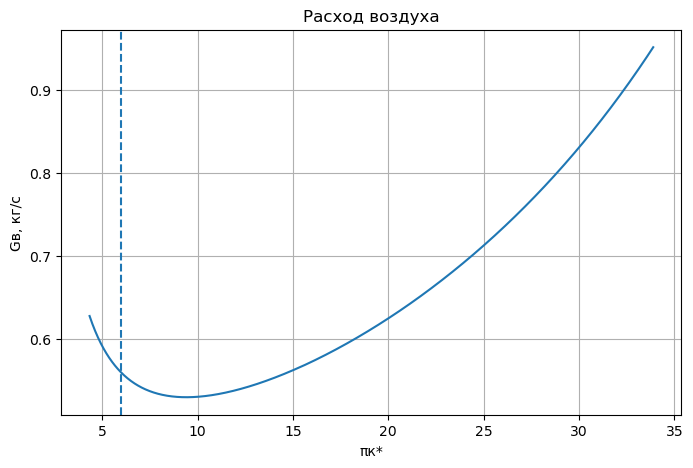

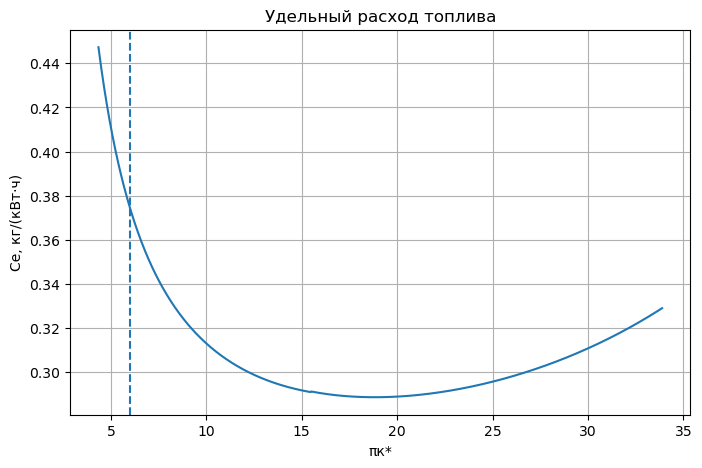

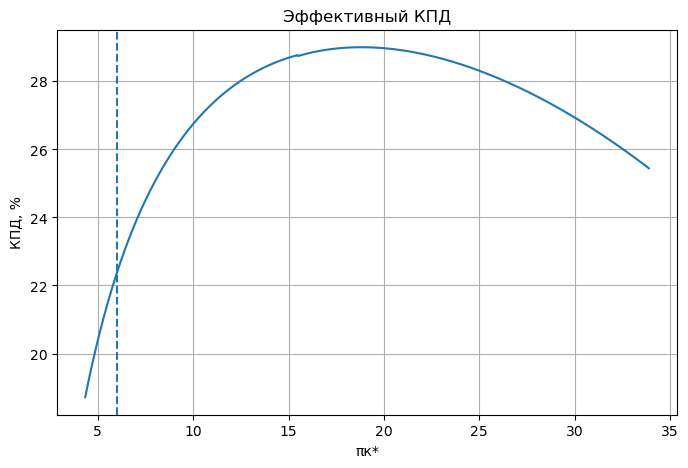

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['G_air'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Gв, кг/с')
plt.title('Расход воздуха')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['Ce_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Ce, кг/(кВт·ч)')
plt.title('Удельный расход топлива')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], 100*variants['eta_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('КПД, %')
plt.title('Эффективный КПД')
plt.grid()
plt.show()

# Проектирование турбины компрессора и силовой турбины

Расчёт выполняется последовательно по направлению газа:

1. проектируется одноступенчатая турбина компрессора (ТК);
2. её выходные полные параметры передаются на вход одноступенчатой силовой турбины (СТ);
3. для обеих турбин используется один закон профилирования
   $D_{\mathrm{вт}}=\mathrm{const}$;
4. выход из обеих турбин принимается осевым:
   $c_{2u}=0$, $\alpha_2=90^\circ$.

Новые обязательные ограничения:

$$15^\circ\leq\alpha_1\leq25^\circ,\qquad \rho_{\mathrm{корень}}\geq0{,}10,\qquad \sigma\leq320\ \text{МПа}.$$

Для СТ дополнительно задаётся рабочий интервал скорости
$200\leq c_{2a}\leq300$ м/с. Целевая высота лопатки РК ТК — не менее 20 мм.


## 1. Исходные данные и критерии подбора

Требуемые удельные работы берутся из расчёта цикла:

$$L_{\mathrm{ТК}}=L_{\mathrm{ГГ}},\qquad L_{\mathrm{СТ}}=L_{\mathrm{СТ,цикл}}.$$

Для каждого сочетания $D_{\mathrm{вт}},\rho,\alpha_1,c_{2a}$ одновременно
подбираются теоретический теплоперепад $H_0$ и частота вращения $n$ из условий

$$L(H_0,n)=L_{\mathrm{треб}},\qquad c_{2u}(H_0,n)=0.$$

После решения проверяются напряжение, корневая реактивность, отношение
$l/D$, числа Маха и осевой выход. Формулы расчёта ступени соответствуют
порядку расчёта на с. 85–91 методического пособия; геометрия при
$D_{\mathrm{вт}}=\mathrm{const}$ — с. 62.


In [15]:
from scipy.optimize import least_squares
import itertools

G_gas_design = s['G_gas']
alpha_design = s['alpha']
phi, psi = 0.97, 0.96
radial_clearance = 0.0005
kn = 6.8e-6

sigma_limit = 320.0          # МПа
alpha1_min, alpha1_max = 15.0, 25.0
rho_root_min = 0.10
l_rotor_target = 0.020       # м
lD_limit = 1 / 3

constraints = pd.Series({
    'Dвт': 'const для ТК и СТ',
    'α1 по среднему сечению': '15–25°',
    'ρ у корня, не менее': rho_root_min,
    'Допустимое напряжение, МПа': sigma_limit,
    'Выход ТК и СТ': 'c2u = 0; α2 = 90°',
    'c2a СТ, м/с': '200–300',
    'Целевая l РК ТК, мм': 1000 * l_rotor_target,
    'Предельное l/D': lD_limit,
})
display(constraints.to_frame('Принято'))


,Принято
Dвт,const для ТК и СТ
α1 по среднему сечению,15–25°
"ρ у корня, не менее",0.1000
"Допустимое напряжение, МПа",320.0000
Выход ТК и СТ,c2u = 0; α2 = 90°
"c2a СТ, м/с",200–300
"Целевая l РК ТК, мм",20.0000
Предельное l/D,0.3333


## 2. Расчёт соплового аппарата и рабочего колеса

Для соплового аппарата:

$$H_c=(1-\rho)H_0,\qquad c_1=\varphi\sqrt{2000H_c},$$

$$T_1=T_0^*-\frac{c_1^2}{2000c_p},\qquad p_1=p_0^*\left(\frac{T_{1\mathrm{ад}}}{T_0^*}\right)^{k/(k-1)}.$$

Площадь и высота проточной части при постоянном втулочном диаметре:

$$A=\frac{Gv}{c_a},\qquad l=\frac{\sqrt{D_{\mathrm{вт}}^2+4A/\pi}-D_{\mathrm{вт}}}{2},\qquad D_{\mathrm{ср}}=D_{\mathrm{вт}}+l.$$

Работа ступени с учётом зазора и трения диска:

$$L=L_u-h_з-h_{\mathrm{тв}},\qquad L_u=\frac{u_1c_{1u}-u_2c_{2u}}{1000}.$$


In [16]:
def calculate_st(H0, n, D_hub, rho, angle1, ca2):
    T0, p0 = T0_st, p0_st
    alpha1 = math.radians(angle1)
    cp = cp_i(T0, alpha_design)
    for _ in range(20):
        T_mean = T0 - H0 * phi**2 / (2 * cp)
        cp = cp_i(T_mean, alpha_design)
    k = cp / (cp - R_gas)

    # Сопловой аппарат
    Hc = H0 * (1 - rho)
    c1 = phi * math.sqrt(2000 * Hc)
    T1 = T0 - phi**2 * Hc / cp
    T1_ad = T0 - Hc / cp
    p1 = p0 * (T1_ad / T0)**(k / (k - 1))
    v1 = R_gas * T1 / p1
    c1a = c1 * math.sin(alpha1)
    c1u = c1 * math.cos(alpha1)
    A1 = G_gas_design * v1 / c1a
    l1 = (math.sqrt(D_hub**2 + 4 * A1 / math.pi) - D_hub) / 2
    D1 = D_hub + l1
    u1 = math.pi * D1 * n / 60
    w1 = math.hypot(c1a, c1u - u1)

    # Рабочее колесо
    Hl = rho * H0 * T1 / T1_ad
    p2 = p1 * (1 - Hl / (cp * T1))**(k / (k - 1))
    c2a = ca2
    l2 = 0.02
    for _ in range(60):
        D2 = D_hub + l2
        u2 = math.pi * D2 * n / 60
        w2 = psi * math.sqrt(w1**2 + 2000 * Hl + u2**2 - u1**2)
        T2 = T1 + (u2**2 - u1**2 - w2**2 + w1**2) / (2000 * cp)
        v2 = R_gas * T2 / p2
        A2 = G_gas_design * v2 / c2a
        l_next = (math.sqrt(D_hub**2 + 4 * A2 / math.pi) - D_hub) / 2
        if abs(l_next - l2) < 1e-12:
            break
        l2 = l_next
    else:
        raise ValueError(f'СТ: площадь за РК не сошлась')
    if c2a >= w2:
        raise ValueError(f'СТ: осевая скорость за РК выше относительной')
    w2u = -math.sqrt(w2**2 - c2a**2)
    c2u = u2 + w2u
    c2 = math.hypot(c2a, c2u)

    # Удельные потери в зазоре и на трение диска при полной подаче
    Lu = (u1 * c1u - u2 * c2u) / 1000
    hc = (1 / phi**2 - 1) * c1**2 / 2000
    hl = (1 / psi**2 - 1) * w2**2 / 2000
    hv = c2**2 / 2000
    hz = 1.37 * (1 + 1.6 * rho) * (1 + l2 / D2) * (radial_clearance / l2) * Lu
    density_mean = (1 / v1 + 1 / v2) / 2
    friction_power = 1.07 * D2**2 * (u2 / 100)**3 * density_mean
    h_friction = friction_power / G_gas_design
    L = Lu - hz - h_friction
    T_exit = T2 + (hz + h_friction) / cp
    T_exit_total = T_exit + hv / cp
    p_exit_total = p2 * (T_exit_total / T_exit)**(k / (k - 1))
    H_total = cp * T0 * (1 - (p_exit_total / p0)**((k - 1) / k))

    return dict(H0=H0, T0=T0, p0=p0, cp=cp, k=k, rho=rho, n=n,
                D_hub=D_hub, D1=D1, D2=D2, l1=l1, l2=l2, A1=A1, A2=A2,
                T1=T1, T2=T2, p1=p1, p2=p2, c1=c1, c1a=c1a, c1u=c1u,
                c2=c2, c2a=c2a, c2u=c2u, w1=w1, w2=w2, u1=u1, u2=u2,
                alpha1=angle1, alpha2=math.degrees(math.atan2(c2a,c2u)),
                beta1=math.degrees(math.atan2(c1a,c1u-u1)),
                beta2=math.degrees(math.atan2(c2a,w2u)),
                Lu=Lu, L=L, hc=hc, hl=hl, hv=hv, hz=hz, h_friction=h_friction,
                T2_total=T_exit_total, p2_total=p_exit_total, eta=L/H_total,
                eta_power=L/H0, sigma=kn*n**2*A2,
                M1=c1/math.sqrt(1000*k*R_gas*T1),
                M2w=w2/math.sqrt(1000*k*R_gas*T2))

In [17]:
def root_reaction(g):
    a = math.radians(g['alpha1'])
    c_root = g['c1']*(g['D1']/g['D_hub'])**math.cos(a)**2
    T_ad = g['T0']-(c_root/phi)**2/(2000*g['cp'])
    if T_ad <= 0:
        return -1.0
    p_root = g['p0']*(T_ad/g['T0'])**(g['k']/(g['k']-1))
    return g['cp']*T_ad*(1-(g['p2']/p_root)**((g['k']-1)/g['k']))/g['H0']

In [18]:
def solve_axial_stage(T0_total, p0_total, L_required,
                      D_hub, rho, alpha1, c2a,
                      initial=(280.0, 90.0)):
    # Подбор H0 и n для требуемой работы и осевого выхода c2u=0.
    global T0_st, p0_st
    T0_old, p0_old = globals().get('T0_st'), globals().get('p0_st')
    T0_st, p0_st = T0_total, p0_total

    def residual(x):
        try:
            stage = calculate_st(
                H0=x[0], n=x[1] * 1000,
                D_hub=D_hub, rho=rho,
                angle1=alpha1, ca2=c2a,
            )
            return [
                (stage['L'] - L_required) / L_required,
                stage['c2u'] / c2a,
            ]
        except (ValueError, OverflowError, ZeroDivisionError):
            return [999.0, 999.0]

    solution = least_squares(
        residual, initial,
        bounds=([140.0, 15.0], [550.0, 220.0]),
        max_nfev=55,
        ftol=5e-9, xtol=5e-9, gtol=5e-9,
    )

    try:
        if (not solution.success or
                max(abs(value) for value in residual(solution.x)) > 2e-6):
            return None

        stage = calculate_st(
            H0=solution.x[0], n=solution.x[1] * 1000,
            D_hub=D_hub, rho=rho,
            angle1=alpha1, ca2=c2a,
        )
        stage['rho_root'] = root_reaction(stage)
        stage['lD_max'] = max(
            stage['l1'] / stage['D1'],
            stage['l2'] / stage['D2'],
        )
        stage['min_height'] = min(stage['l1'], stage['l2'])
        return stage
    finally:
        T0_st, p0_st = T0_old, p0_old


def stage_is_valid(stage):
    return (
        stage is not None
        and alpha1_min <= stage['alpha1'] <= alpha1_max
        and stage['rho_root'] >= rho_root_min
        and stage['sigma'] <= sigma_limit
        and stage['lD_max'] <= lD_limit
        and max(stage['M1'], stage['M2w']) < 1.2
        and abs(stage['c2u']) < 1e-3
    )


def stage_row(name, stage):
    return {
        'Турбина': name,
        'Dвт, мм': 1000 * stage['D_hub'],
        'ρ среднего сечения': stage['rho'],
        'ρ у корня': stage['rho_root'],
        'α1, град': stage['alpha1'],
        'α2, град': stage['alpha2'],
        'c2a, м/с': stage['c2a'],
        'c2u, м/с': stage['c2u'],
        'n, об/мин': stage['n'],
        'H0, кДж/кг': stage['H0'],
        'L, кДж/кг': stage['L'],
        'l СА, мм': 1000 * stage['l1'],
        'l РК, мм': 1000 * stage['l2'],
        'σ, МПа': stage['sigma'],
        'max(l/D)': stage['lD_max'],
        'p2*, кПа': stage['p2_total'],
        'T2*, К': stage['T2_total'],
    }


## 3. Подбор турбины компрессора

Для ТК перебираются втулочный диаметр, реактивность и угол $\alpha_1$.
Для максимизации высоты лопатки РК принимается нижняя исследуемая граница
$c_{2a,\mathrm{ТК}}=120$ м/с, поскольку

$$A_2=\frac{Gv_2}{c_{2a}},$$

и увеличение $c_{2a}$ при прочих равных уменьшает выходную площадь и высоту лопатки.
Для каждого варианта заново решаются уравнения работы и осевого выхода.


In [19]:
L_tk_required = s['L_gg']
tk_candidates = []

for D_hub, rho, alpha1 in itertools.product(
        np.arange(0.070, 0.091, 0.001),
        np.arange(0.30, 0.551, 0.01),
        np.arange(15.0, 25.01, 1.0)):
    stage = solve_axial_stage(
        T0_total=s['Tg'], p0_total=s['pg'],
        L_required=L_tk_required,
        D_hub=float(D_hub), rho=float(rho),
        alpha1=float(alpha1), c2a=120.0,
        initial=(280.0, 90.0),
    )
    if stage_is_valid(stage):
        stage['pressure_error'] = stage['p2_total'] / s['p4'] - 1
        tk_candidates.append(stage)

tk_candidates.sort(key=lambda stage: (
    -stage['l2'], -stage['l1'],
    abs(stage['pressure_error']), stage['sigma'],
))

print('Допустимых вариантов ТК:', len(tk_candidates))
print('Из них l РК ТК ≥ 20 мм:',
      sum(stage['l2'] >= l_rotor_target for stage in tk_candidates))

tk_selected = tk_candidates[0]
tk_top = pd.DataFrame([
    stage_row('ТК', stage) | {
        'Отклонение p2* от цикла, %': 100 * stage['pressure_error']
    }
    for stage in tk_candidates[:10]
])
display(tk_top)


Допустимых вариантов ТК: 345
Из них l РК ТК ≥ 20 мм: 0


,Турбина,"Dвт, мм",ρ среднего сечения,ρ у корня,"α1, град","α2, град","c2a, м/с","c2u, м/с","n, об/мин","H0, кДж/кг","L, кДж/кг","l СА, мм","l РК, мм","σ, МПа",max(l/D),"p2*, кПа","T2*, К","Отклонение p2* от цикла, %"
0,ТК,80.0000,0.3200,0.1130,15.0000,90.0000,120.0000,-0.0000,90257.1150,279.2079,233.3292,12.2454,18.6184,319.5375,0.1888,250.9714,1057.0043,-5.0358
1,ТК,80.0000,0.3000,0.1014,16.0000,90.0000,120.0000,0.0000,89919.0605,279.0777,233.3292,11.5748,18.6166,317.1116,0.1888,251.0829,1057.0058,-4.9936
2,ТК,80.0000,0.3100,0.1000,15.0000,90.0000,120.0000,0.0000,89555.4604,279.0012,233.3292,12.2413,18.6103,314.4256,0.1887,251.1485,1057.0067,-4.9687
3,ТК,81.0000,0.3000,0.1186,17.0000,90.0000,120.0000,0.0000,90089.3873,279.4634,233.3292,10.8763,18.4772,318.6871,0.1857,250.7527,1057.0013,-5.1185
4,ТК,81.0000,0.3300,0.1306,15.0000,90.0000,120.0000,-0.0000,90136.2484,279.5420,233.3292,12.1342,18.4739,318.9521,0.1857,250.6854,1057.0004,-5.1440
5,ТК,81.0000,0.3100,0.1187,16.0000,90.0000,120.0000,0.0000,89771.2473,279.3979,233.3292,11.4661,18.4714,316.3241,0.1857,250.8087,1057.0021,-5.0973
6,ТК,81.0000,0.3200,0.1178,15.0000,90.0000,120.0000,0.0000,89426.9921,279.3269,233.3292,12.1290,18.4654,313.7817,0.1856,250.8695,1057.0029,-5.0743
7,ТК,81.0000,0.3000,0.1060,16.0000,90.0000,120.0000,0.0000,89080.7705,279.1910,233.3292,11.4635,18.4634,311.3155,0.1856,250.9859,1057.0045,-5.0303
8,ТК,81.0000,0.3100,0.1049,15.0000,90.0000,120.0000,0.0000,88731.3339,279.1184,233.3292,12.1251,18.4573,308.7574,0.1856,251.0480,1057.0053,-5.0067
9,ТК,82.0000,0.3100,0.1352,17.0000,90.0000,120.0000,0.0000,89938.9253,279.7893,233.3292,10.7736,18.3343,317.8841,0.1827,250.4738,1056.9975,-5.2240


## 4. Подбор силовой турбины

На вход СТ передаются полные параметры выбранной ТК:

$$T_{0,\mathrm{СТ}}^*=T_{2,\mathrm{ТК}}^*,\qquad p_{0,\mathrm{СТ}}^*=p_{2,\mathrm{ТК}}^*.$$

Втулочный диаметр остаётся тем же. Для СТ перебираются реактивность,
$\alpha_1=15\text{–}25^\circ$ и $c_{2a}=200\text{–}300$ м/с.


In [20]:
L_st_required = s['L_pt']
st_candidates = []

for rho, alpha1, c2a in itertools.product(
        np.arange(0.30, 0.601, 0.01),
        np.arange(15.0, 25.01, 1.0),
        np.arange(200.0, 301.0, 10.0)):
    stage = solve_axial_stage(
        T0_total=tk_selected['T2_total'],
        p0_total=tk_selected['p2_total'],
        L_required=L_st_required,
        D_hub=tk_selected['D_hub'],
        rho=float(rho), alpha1=float(alpha1), c2a=float(c2a),
        initial=(252.0, 80.0),
    )
    if stage_is_valid(stage):
        stage['pressure_error_static'] = stage['p2'] / s['p5'] - 1
        stage['pressure_error_total'] = stage['p2_total'] / s['p5_total'] - 1
        st_candidates.append(stage)

st_candidates.sort(key=lambda stage: (
    abs(stage['pressure_error_static']),
    -stage['min_height'], stage['sigma'],
))

# Среди вариантов практически с минимальной невязкой давления выбираем
# вариант с большим запасом корневой реактивности.
best_pressure_error = abs(st_candidates[0]['pressure_error_static'])
near_best_st = [
    stage for stage in st_candidates
    if abs(stage['pressure_error_static']) <= best_pressure_error + 0.0002
]
st_selected = max(near_best_st, key=lambda stage: (
    stage['rho_root'], stage['min_height'], -stage['sigma']
))

print('Допустимых вариантов СТ:', len(st_candidates))
display(pd.DataFrame([
    stage_row('СТ', stage) | {
        'Отклонение p2 стат. от цикла, %':
            100 * stage['pressure_error_static']
    }
    for stage in st_candidates[:10]
]))


Допустимых вариантов СТ: 1330


,Турбина,"Dвт, мм",ρ среднего сечения,ρ у корня,"α1, град","α2, град","c2a, м/с","c2u, м/с","n, об/мин","H0, кДж/кг","L, кДж/кг","l СА, мм","l РК, мм","σ, МПа",max(l/D),"p2*, кПа","T2*, К","Отклонение p2 стат. от цикла, %"
0,СТ,80.0000,0.4300,0.1057,16.0000,90.0000,200.0000,-0.0000,80335.2414,251.5840,199.9632,22.0818,21.9826,309.0838,0.2163,107.8366,886.3238,-5.4277
1,СТ,80.0000,0.4500,0.1136,15.0000,90.0000,200.0000,0.0000,80520.5023,251.6107,199.9632,23.3166,21.9793,310.4548,0.2257,107.8247,886.3235,-5.4381
2,СТ,80.0000,0.4000,0.1013,18.0000,90.0000,200.0000,0.0000,80596.6163,251.6719,199.9632,20.0222,21.9968,311.3428,0.2157,107.7974,886.3227,-5.4620
3,СТ,80.0000,0.4200,0.1115,17.0000,90.0000,200.0000,0.0000,80834.2687,251.7049,199.9632,21.0073,21.9940,313.1331,0.2156,107.7827,886.3222,-5.4749
4,СТ,80.0000,0.4400,0.1209,16.0000,90.0000,200.0000,0.0000,81061.4423,251.7395,199.9632,22.1108,21.9913,314.8486,0.2165,107.7674,886.3218,-5.4884
5,СТ,80.0000,0.4600,0.1291,15.0000,90.0000,200.0000,0.0000,81267.9815,251.7732,199.9632,23.3536,21.9885,316.4065,0.2260,107.7524,886.3214,-5.5016
6,СТ,80.0000,0.3900,0.1047,19.0000,90.0000,200.0000,0.0000,81038.6638,251.7835,199.9632,19.1515,22.0075,314.9540,0.2157,107.7478,886.3212,-5.5056
7,СТ,80.0000,0.4100,0.1159,18.0000,90.0000,200.0000,0.0000,81297.8296,251.8197,199.9632,20.0407,22.0050,316.9267,0.2157,107.7317,886.3207,-5.5198
8,СТ,80.0000,0.4300,0.1265,17.0000,90.0000,200.0000,0.0000,81555.6920,251.8596,199.9632,21.0321,22.0027,318.8997,0.2157,107.7139,886.3202,-5.5353
9,СТ,80.0000,0.3800,0.1070,20.0000,90.0000,200.0000,0.0000,81462.1404,251.8925,199.9632,18.3609,22.0181,318.4396,0.2158,107.6993,886.3198,-5.5482


## 5. Выбранная пара ТК–СТ

Ниже приведена согласованная пара с общим втулочным диаметром,
осевым выходом из обеих турбин и всеми заданными проверками.


In [21]:
result_table = pd.DataFrame([
    stage_row('ТК', tk_selected),
    stage_row('СТ', st_selected),
]).set_index('Турбина')

display(result_table)

checks = pd.DataFrame({
    'Проверка': [
        'Общий Dвт',
        'α1 = 15–25°',
        'ρ у корня ≥ 0,10',
        'σ ≤ 320 МПа',
        'Осевой выход c2u = 0',
        'c2 СТ = 200–300 м/с',
        'l/D ≤ 1/3',
        'l РК ТК ≥ 20 мм',
    ],
    'Выполнено': [
        abs(tk_selected['D_hub'] - st_selected['D_hub']) < 1e-12,
        all(alpha1_min <= x['alpha1'] <= alpha1_max
            for x in (tk_selected, st_selected)),
        all(x['rho_root'] >= rho_root_min
            for x in (tk_selected, st_selected)),
        all(x['sigma'] <= sigma_limit
            for x in (tk_selected, st_selected)),
        all(abs(x['c2u']) < 1e-3
            for x in (tk_selected, st_selected)),
        200 <= st_selected['c2'] <= 300,
        all(x['lD_max'] <= lD_limit
            for x in (tk_selected, st_selected)),
        tk_selected['l2'] >= l_rotor_target,
    ],
})
display(checks)


,"Dвт, мм",ρ среднего сечения,ρ у корня,"α1, град","α2, град","c2a, м/с","c2u, м/с","n, об/мин","H0, кДж/кг","L, кДж/кг","l СА, мм","l РК, мм","σ, МПа",max(l/D),"p2*, кПа","T2*, К"
Турбина,,,,,,,,,,,,,,,,
ТК,80.0000,0.3200,0.1130,15.0000,90.0000,120.0000,-0.0000,90257.1150,279.2079,233.3292,12.2454,18.6184,319.5375,0.1888,250.9714,1057.0043
СТ,80.0000,0.4500,0.1136,15.0000,90.0000,200.0000,0.0000,80520.5023,251.6107,199.9632,23.3166,21.9793,310.4548,0.2257,107.8247,886.3235


,Проверка,Выполнено
0,Общий Dвт,True
1,α1 = 15–25°,True
2,"ρ у корня ≥ 0,10",True
3,σ ≤ 320 МПа,True
4,Осевой выход c2u = 0,True
5,c2 СТ = 200–300 м/с,True
6,l/D ≤ 1/3,True
7,l РК ТК ≥ 20 мм,False


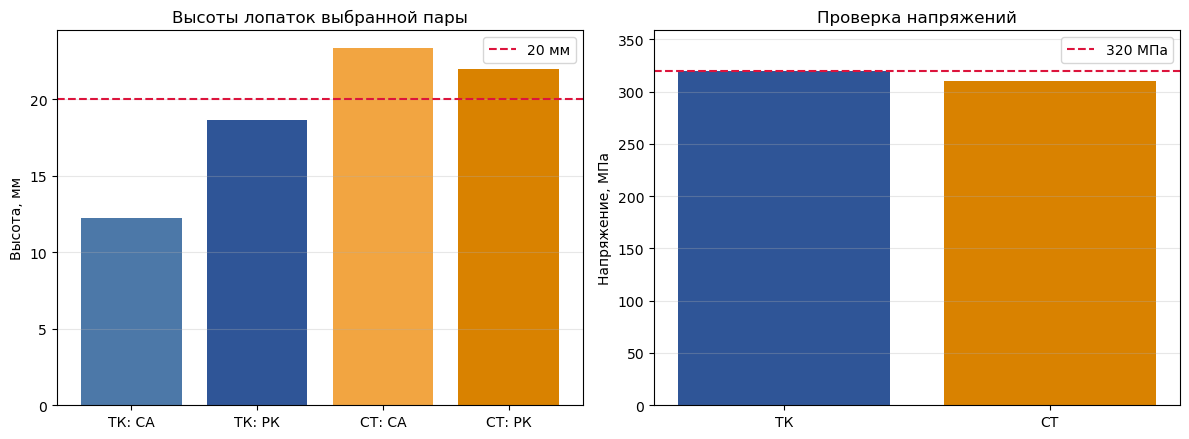

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels = ['ТК: СА', 'ТК: РК', 'СТ: СА', 'СТ: РК']
heights = [
    1000 * tk_selected['l1'], 1000 * tk_selected['l2'],
    1000 * st_selected['l1'], 1000 * st_selected['l2'],
]
colors = ['#4C78A8', '#2F5597', '#F2A541', '#D98200']
axes[0].bar(labels, heights, color=colors)
axes[0].axhline(20, color='crimson', linestyle='--', label='20 мм')
axes[0].set_ylabel('Высота, мм')
axes[0].set_title('Высоты лопаток выбранной пары')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend()

stress_values = [tk_selected['sigma'], st_selected['sigma']]
axes[1].bar(['ТК', 'СТ'], stress_values,
            color=['#2F5597', '#D98200'])
axes[1].axhline(sigma_limit, color='crimson', linestyle='--',
                label=f'{sigma_limit:.0f} МПа')
axes[1].set_ylabel('Напряжение, МПа')
axes[1].set_title('Проверка напряжений')
axes[1].set_ylim(0, 1.12 * sigma_limit)
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


## 6. Итог

После введения ограничений

$$15^\circ\leq\alpha_1\leq25^\circ,\qquad \rho_{\mathrm{корень}}\geq0{,}10,\qquad \sigma\leq320\ \text{МПа}$$

получена следующая пара:

- общий $D_{\mathrm{вт}}=80$ мм;
- ТК: $\rho=0{,}32$, $\alpha_1=15^\circ$,
  $c_2=120$ м/с, $l_{\mathrm{РК}}=18{,}62$ мм,
  $\sigma=319{,}54$ МПа, $\rho_{\mathrm{корень}}=0{,}113$;
- СТ: $\rho=0{,}45$, $\alpha_1=15^\circ$,
  $c_2=200$ м/с, $l_{\mathrm{РК}}=21{,}98$ мм,
  $\sigma=310{,}45$ МПа, $\rho_{\mathrm{корень}}=0{,}114$;
- для обеих турбин $c_{2u}=0$ и $\alpha_2=90^\circ$.

Все ограничения, кроме целевой высоты РК ТК, выполнены. На исследованной
сетке максимальная допустимая высота РК ТК равна 18,62 мм, поэтому условие
$l_{\mathrm{РК,ТК}}\geq20$ мм пока не достигается.
